In [15]:
import pandas as pd

In [2]:
df = pd.read_csv("enterprise_vector_db_benchmarks_2026.csv")

In [3]:
df.head()

,benchmark_id,database_engine,engine,indexing_algorithm,index_type,quantization_type,quantization,vector_dimensions,dataset_scale_millions,top_k,...,recall_at_100,ram_usage_gb,ram_gb,server_cpu_utilization_pct,query_cache_hit_rate_pct,engine_version,deployment_architecture,index_build_time_minutes,write_throughput_eps,estimated_monthly_tco_usd
0,06f9fa78-71c8-42a9-9a60-c348ab71c50a,ClickHouse,ClickHouse,IVF-PQ,IVF-PQ,INT4,INT4,384,50.0,1,...,0.8936,6.22,6.22,17.2,90.6,v2026.1-enterprise,Cluster,225.00,874.0,153.47
1,3a4f03a0-79bd-4f3c-bee5-cefc8b52233a,Milvus,Milvus,IVF-PQ,IVF-PQ,INT8 (SQ8),INT8 (SQ8),1536,10.0,1,...,0.9327,10.35,10.35,11.9,62.8,v2026.1-enterprise,Cluster,45.00,494.0,196.28
2,c32c7ed3-7536-47be-a80d-a5700f59def6,Qdrant,Qdrant,HNSW,HNSW,INT8 (SQ8),INT8 (SQ8),512,0.5,100,...,0.9810,0.34,0.34,52.3,86.0,v2026.1-enterprise,Cluster,2.25,17231.0,313.49
3,10e1ec30-e96f-41b1-a484-3430d53b2451,Weaviate,Weaviate,HNSW,HNSW,INT4,INT4,3072,5.0,5,...,0.9464,12.01,12.01,20.2,70.1,v2026.1-enterprise,Cluster,22.50,1795.0,298.98
4,03b6ce9d-a41f-4dbe-afe3-ad87be7f65a9,Pinecone,Pinecone,IVF-PQ,IVF-PQ,FP32 (None),FP32 (None),3072,0.5,10,...,0.9539,4.04,4.04,31.0,65.2,v2026.1-enterprise,Cluster,2.25,1318.0,151.54


## Exploratory Data Analysis (EDA)

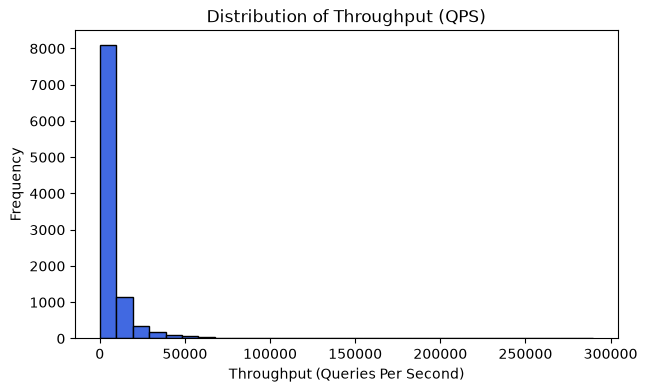

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(df['throughput_qps'], bins=30, color='royalblue', edgecolor='black')
plt.title('Distribution of Throughput (QPS)')
plt.xlabel('Throughput (Queries Per Second)')
plt.ylabel('Frequency')
plt.show()

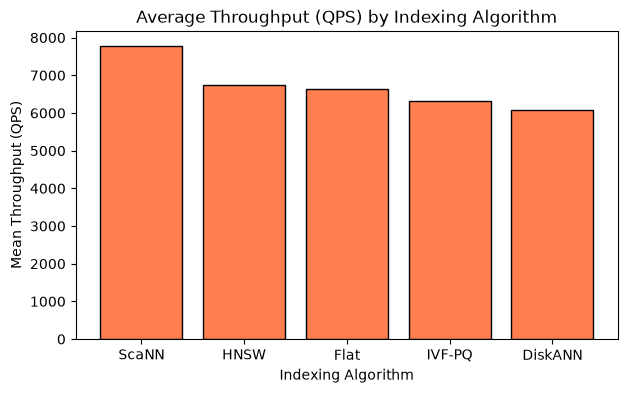

In [5]:
avg_algo = df.groupby('indexing_algorithm')['throughput_qps'].mean().sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(avg_algo.index, avg_algo.values, color='coral', edgecolor='black')
plt.title('Average Throughput (QPS) by Indexing Algorithm')
plt.xlabel('Indexing Algorithm')
plt.ylabel('Mean Throughput (QPS)')
plt.show()

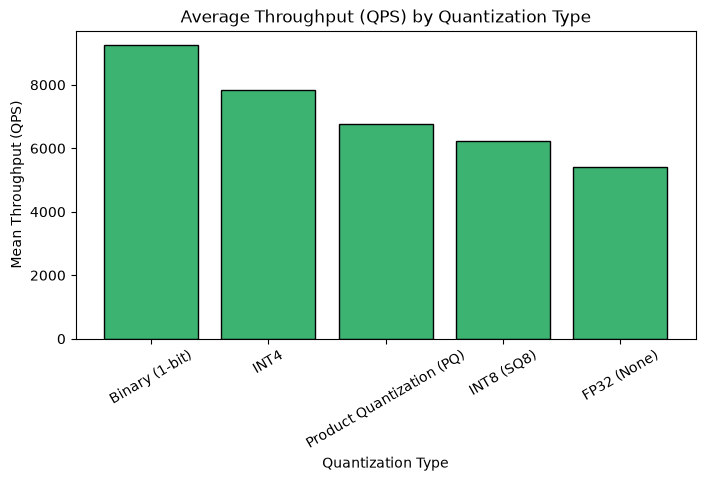

In [6]:
avg_quant = df.groupby('quantization_type')['throughput_qps'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(avg_quant.index, avg_quant.values, color='mediumseagreen', edgecolor='black')
plt.title('Average Throughput (QPS) by Quantization Type')
plt.xlabel('Quantization Type')
plt.ylabel('Mean Throughput (QPS)')
plt.xticks(rotation=30)
plt.show()

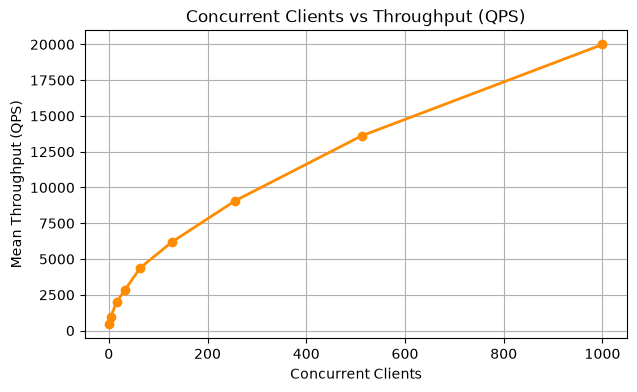

In [7]:
avg_clients = df.groupby('concurrent_clients')['throughput_qps'].mean()

plt.figure(figsize=(7, 4))
plt.plot(avg_clients.index, avg_clients.values, marker='o', color='darkorange', linewidth=2)
plt.title('Concurrent Clients vs Throughput (QPS)')
plt.xlabel('Concurrent Clients')
plt.ylabel('Mean Throughput (QPS)')
plt.grid(True)
plt.show()

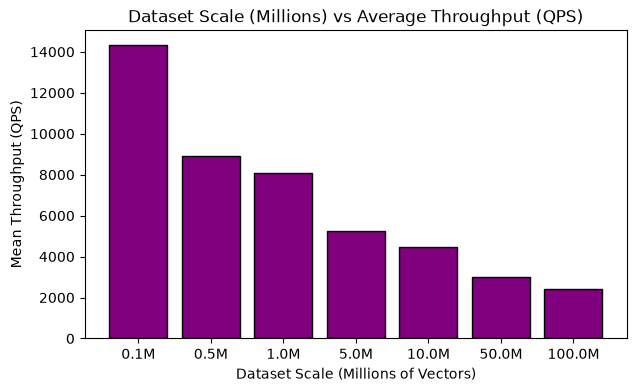

In [8]:
avg_scale = df.groupby('dataset_scale_millions')['throughput_qps'].mean()

plt.figure(figsize=(7, 4))
plt.bar(avg_scale.index.astype(str) + 'M', avg_scale.values, color='purple', edgecolor='black')
plt.title('Dataset Scale (Millions) vs Average Throughput (QPS)')
plt.xlabel('Dataset Scale (Millions of Vectors)')
plt.ylabel('Mean Throughput (QPS)')
plt.show()

## Model Building (Index Benefit Prediction Pipeline)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [10]:
num_cols = ['vector_dimensions', 'dataset_scale_millions', 'top_k', 'concurrent_clients']
cat_cols = ['database_engine', 'indexing_algorithm', 'quantization_type', 'hardware_config', 'use_case']

X = df[num_cols + cat_cols]
y = df['throughput_qps']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [12]:
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['vector_dimensions','dataset_scale_millions','top_k',..., 'quantization_type','hardware_config','use_case']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically

In [13]:
y_pred = model_pipeline.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", mean_squared_error(y_test, y_pred) ** 0.5)

R2 Score: 0.8225176119877318
Mean Absolute Error (MAE): 1874.4134049250001
Root Mean Squared Error (RMSE): 4615.087853809075


In [14]:
import joblib

joblib.dump(model_pipeline, 'index_benefit_model.pkl')
print("Model successfully exported as 'index_benefit_model.pkl'!")

Model successfully exported as 'index_benefit_model.pkl'!
